In [ ]:
"""
Лабораторная работа № 7. Построение автокодировщика**
Вариант:** 21.
Исследуемый фактор: архитектура автокодировщика — свёрточная или полносвязная.
Набор данных: цветной диск с изменяемыми положением, радиусом и оттенком. Всего четыре параметра сцены.
Гипотеза: свёрточный автокодировщик обеспечит более высокое качество реконструкции цветного диска, поскольку свёрточные слои учитывают пространственную структуру изображения. Полносвязная архитектура может показать отличающиеся результаты по PSNR, количеству параметров и времени обучения.
Режим A: свёрточный автокодировщик, латентный вектор d = 8, функция потерь MSE.
Режим B: полносвязный автокодировщик, латентный вектор d = 8, функция потерь MSE.
Фиксируемые параметры: 4096 обучающих изображений, 1024 тестовых изображения, 20 эпох, оптимизатор Adam, скорость обучения 0,002, размер пакета 128.
Серия запусков: пять seed — 101, 102, 103, 104, 105.
Практические допуски: PSNR — ±1,0 дБ; разрыв train − test — ±0,1 дБ; время обучения — ±20 %.
Дата фиксации гипотезы и допусков: 03.11
"""
"""
Метрика	                 Допуск
PSNR	                   ±1,0 дБ
Разрыв train − test	     ±0,1 дБ
Время обучения	         ±20%
"""

In [1]:
# Проверяем GPU и записываем параметры среды:
!nvidia-smi

import sys
import torch
import datetime

print("Дата и время:", datetime.datetime.now())
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ВНИМАНИЕ: GPU не обнаружен")

Wed Nov  4 20:32:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Загружаем файлы лабораторной из файла формата .rar
from google.colab import files

uploaded = files.upload()

Saving ЛР07_Построение_автокодировщика.zip to ЛР07_Построение_автокодировщика.zip


In [3]:
# И выгрузим все в колаб:
import zipfile
import os
import shutil

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, "r") as archive:
    archive.extract("src/lab07_lib.py", "/content/lr07")
    archive.extract("src/lab07_demo.py", "/content/lr07")

shutil.copy("/content/lr07/src/lab07_lib.py", "/content/lab07_lib.py")
shutil.copy("/content/lr07/src/lab07_demo.py", "/content/lab07_demo.py")

print("Файлы подготовлены:")
print(os.listdir("/content"))

Файлы подготовлены:
['.config', 'lab07_lib.py', 'lab07_demo.py', '.ipynb_checkpoints', 'ЛР07_Построение_автокодировщика.zip', 'lr07', 'sample_data']


In [4]:
# Проверяем настройки варианта 21
import lab07_lib as L

N = 21

c, k = (N - 1) // 6, (N - 1) % 6

a_cfg, b_cfg = L.settings(L.FACTORS[k])

print("Номер варианта:", N)
print("Набор данных:", L.KINDS[c])
print("Исследуемый фактор:", L.FACTORS[k])
print("Режим A:", a_cfg)
print("Режим B:", b_cfg)

Номер варианта: 21
Набор данных: disc_color
Исследуемый фактор: arch_conv_to_dense
Режим A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
Режим B: {'arch': 'dense', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}


In [5]:
# Запускаем серию из пяти экспериментов
result = L.variant_summary(21)

print("Результаты эксперимента:")
print("Вариант:", result["variant"])
print("Набор данных:", L.KINDS[result["ctx"] - 1])
print("Фактор:", result["factor"])

print("\nТаблица метрик:")
print(f"{'Метрика':<12} {'A':>12} {'s':>12} {'B':>12} {'Δ':>12} {'|Δ|/s':>12} {'|Δ| > 2s':>12}")

for metric, a, s, b, delta, ratio, significant in result["rows"]:
    print(
        f"{metric:<12} "
        f"{a:>12.4f} "
        f"{s:>12.4f} "
        f"{b:>12.4f} "
        f"{delta:>12.4f} "
        f"{ratio:>12.4f} "
        f"{str(significant):>12}"
    )

Результаты эксперимента:
Вариант: 21
Набор данных: disc_color
Фактор: arch_conv_to_dense

Таблица метрик:
Метрика                 A            s            B            Δ        |Δ|/s     |Δ| > 2s
psnr              21.0941       1.0745      24.6924       3.5984       3.3488         True
gap                0.0908       0.0561       0.1836       0.0928       1.6557        False
params           101.0350       0.0000    1580.5520    1479.5170          inf         True
seconds            1.9031       0.0764       1.1937      -0.7094       9.2861         True


In [ ]:
"""
Качество восстановления. DenseAE показал PSNR на 3.619 дБ выше, чем ConvAE. В данном эксперименте полносвязная архитектура лучше восстановила тестовые изображения.
Разрыв между обучающей и тестовой выборками. У DenseAE разрыв больше: 0.1836 против 0.0988.
Это указывает на более выраженное различие между качеством на обучающих и тестовых данных, хотя само по себе ещё не доказывает переобучение.
Количество параметров. У DenseAE параметров значительно больше. Поэтому улучшение PSNR сопровождается существенным увеличением размера модели.
Время обучения. В этом запуске DenseAE обучился быстрее: 1.1565 с против 1.8192 с. Это результат конкретного окружения и запуска, а не гарантия, что полносвязная модель всегда быстрее.
"""

In [6]:
import torch
import lab07_lib as L

# Загружаем обучающую и тестовую выборки
Xtr, Xte, Ftr, Fte = L.dataset("disc_color")

# Вычисляем среднее изображение обучающей выборки
mean_image = Xtr.mean(dim=0, keepdim=True)

# Повторяем среднее изображение для всей тестовой выборки
baseline_images = mean_image.repeat(Xte.shape[0], 1, 1, 1)

# Вычисляем базовый PSNR
baseline_psnr = L.psnr_images(Xte, baseline_images)

print("Базовый метод — среднее изображение")
print("Размер обучающей выборки:", len(Xtr))
print("Размер тестовой выборки:", len(Xte))
print("Размер среднего изображения:", tuple(mean_image.shape))
print(f"Baseline PSNR: {baseline_psnr:.4f} дБ")

Базовый метод — среднее изображение
Размер обучающей выборки: 4096
Размер тестовой выборки: 1024
Размер среднего изображения: (1, 3, 32, 32)
Baseline PSNR: 18.1203 дБ


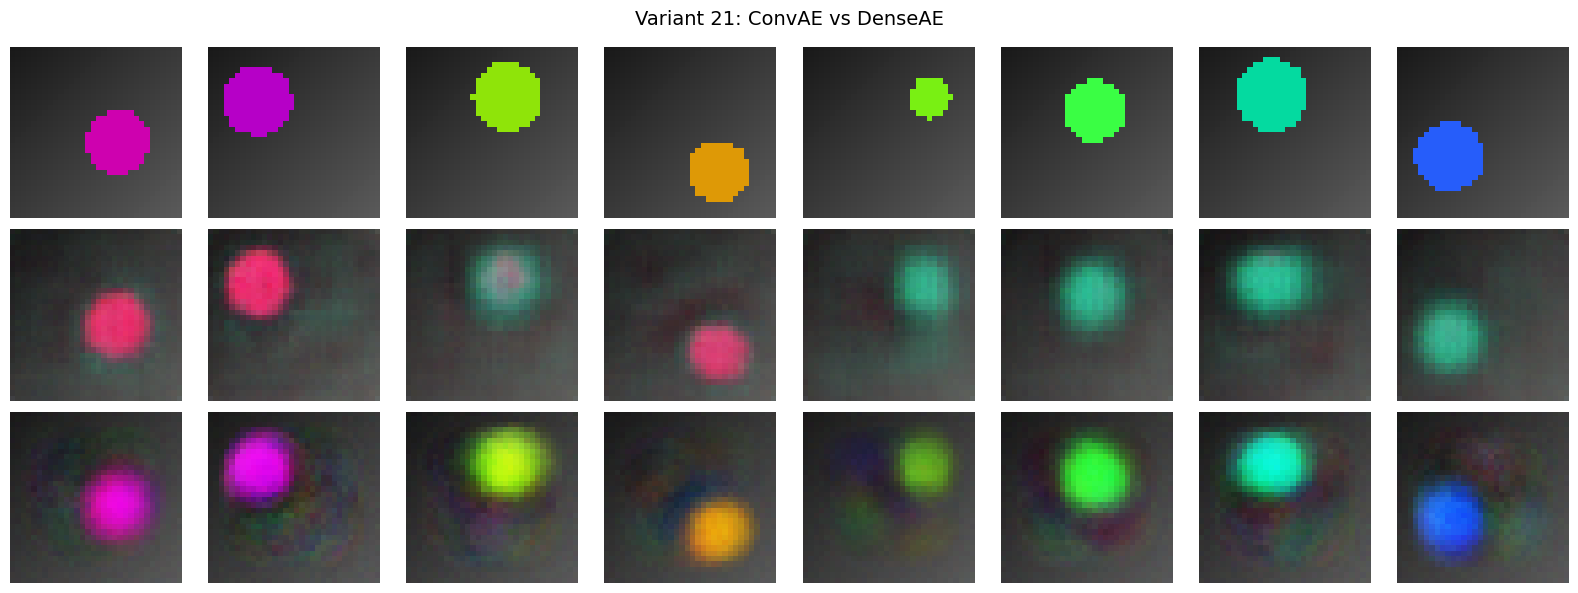

Сравнение сохранено в comparison.png


In [7]:
import torch
import matplotlib.pyplot as plt
import lab07_lib as L

# Настройки варианта 21
kind = "disc_color"
a_cfg, b_cfg = L.settings("arch_conv_to_dense")

# Загружаем тестовую выборку
Xtr, Xte, Ftr, Fte = L.dataset(kind)

# Обучаем обе модели с одинаковым seed
metrics_a, model_a = L.run(kind, a_cfg, seed=101)
metrics_b, model_b = L.run(kind, b_cfg, seed=101)

# Берём первые 8 тестовых изображений
samples = Xte[:8]

# Получаем восстановленные изображения
with torch.no_grad():
    reconstructed_a = L.reconstruct(model_a, samples)
    reconstructed_b = L.reconstruct(model_b, samples)

# Переносим изображения с GPU в CPU для отображения
original = samples.detach().cpu()
reconstructed_a = reconstructed_a.detach().cpu()
reconstructed_b = reconstructed_b.detach().cpu()

# Создаём сравнительную таблицу
fig, axes = plt.subplots(3, 8, figsize=(16, 6))

rows = [
    ("Original", original),
    ("ConvAE", reconstructed_a),
    ("DenseAE", reconstructed_b)
]

for row_idx, (row_name, images) in enumerate(rows):
    for col_idx in range(8):
        img = images[col_idx].permute(1, 2, 0).numpy()
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].axis("off")

    axes[row_idx, 0].set_ylabel(
        row_name,
        fontsize=12,
        rotation=90,
        labelpad=15
    )

plt.suptitle("Variant 21: ConvAE vs DenseAE", fontsize=14)
plt.tight_layout()

plt.savefig("comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Сравнение сохранено в comparison.png")

In [8]:
# Исследуем размерности латентного пространства
import lab07_lib as L

kind = "disc_color"
latent_dims = [1, 2, 3, 4, 8]

a_cfg, b_cfg = L.settings("arch_conv_to_dense")

results = []

for arch, base_cfg in [("conv", a_cfg), ("dense", b_cfg)]:
    print(f"\nАрхитектура: {arch.upper()}")

    for d in latent_dims:
        cfg = base_cfg.copy()
        cfg["d"] = d

        metrics, model = L.run(kind, cfg, seed=101)

        results.append({
            "architecture": arch,
            "latent_dim": d,
            "metrics": metrics
        })

        print(f"d = {d}: {metrics}")

print("\nИсследование завершено.")


Архитектура: CONV
d = 1: {'psnr': 18.85675048828125, 'gap': 0.06906509399414062, 'params': 86.692, 'seconds': 2.3404501869999876}
d = 2: {'psnr': 19.204509735107422, 'gap': 0.0648345947265625, 'params': 88.741, 'seconds': 1.8105658709999943}
d = 3: {'psnr': 19.320215225219727, 'gap': 0.07156181335449219, 'params': 90.79, 'seconds': 1.8357898760000353}
d = 4: {'psnr': 20.388980865478516, 'gap': 0.06690216064453125, 'params': 92.839, 'seconds': 2.3445130510000354}
d = 8: {'psnr': 21.634279251098633, 'gap': 0.06749153137207031, 'params': 101.035, 'seconds': 3.601661637999996}

Архитектура: DENSE
d = 1: {'psnr': 18.769569396972656, 'gap': 0.08158111572265625, 'params': 1576.961, 'seconds': 1.596500659999947}
d = 2: {'psnr': 20.099288940429688, 'gap': 0.1626300811767578, 'params': 1577.474, 'seconds': 1.1506419759999744}
d = 3: {'psnr': 22.06601333618164, 'gap': 0.18299484252929688, 'params': 1577.987, 'seconds': 1.2074374300000272}
d = 4: {'psnr': 24.0733642578125, 'gap': 0.16245651245117

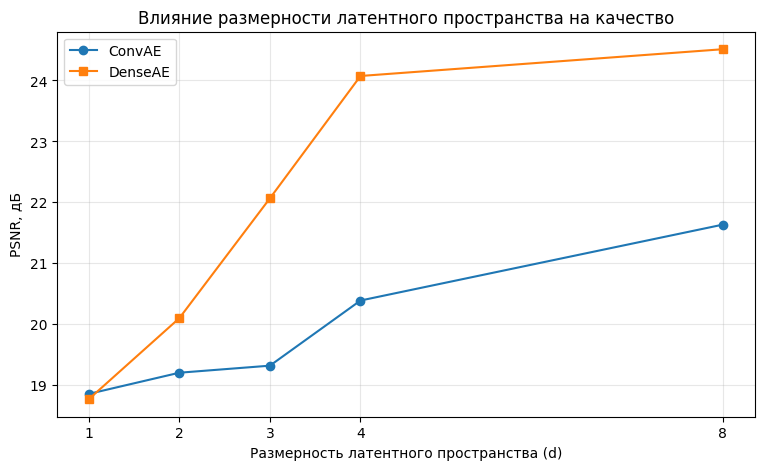

In [9]:
# Построим график зависимости PSNR от размерности:
import matplotlib.pyplot as plt

conv_psnr = [18.8568, 19.2045, 19.3202, 20.3890, 21.6343]
dense_psnr = [18.7696, 20.0993, 22.0660, 24.0734, 24.5124]
latent_dims = [1, 2, 3, 4, 8]

plt.figure(figsize=(9, 5))

plt.plot(latent_dims, conv_psnr, marker="o", label="ConvAE")
plt.plot(latent_dims, dense_psnr, marker="s", label="DenseAE")

plt.xlabel("Размерность латентного пространства (d)")
plt.ylabel("PSNR, дБ")
plt.title("Влияние размерности латентного пространства на качество")
plt.xticks(latent_dims)
plt.grid(True, alpha=0.3)
plt.legend()

plt.savefig("latent_dimension_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
"""
При увеличении размерности латентного пространства качество восстановления изображений повышается для обеих архитектур.
Однако DenseAE демонстрирует более выраженный прирост PSNR и начиная с d=2 превосходит ConvAE.
При d=4 DenseAE достигает PSNR 24,07 дБ, тогда как ConvAE при d=8 показывает 21,63 дБ.
Вместе с тем DenseAE характеризуется большим разрывом между обучающей и тестовой выборками.
Таким образом, увеличение размерности улучшает качество восстановления, но при выборе архитектуры необходимо учитывать не только PSNR, но и разрыв между выборками, вычислительные затраты и количество параметров.
"""

In [10]:
# Зафиксируем сведения о среде выполнения
import sys
import torch
import platform

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Платформа:", platform.platform())
print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Версия CUDA:", torch.version.cuda)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Платформа: Linux-6.6.159+-x86_64-with-glibc2.39
CUDA доступна: True
GPU: Tesla T4
Версия CUDA: 13.0
